# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Method: continuous, convex piecewise-linear IFR interpolation

The inputs are instantaneous-forward **point values** $f_i=f(t_i)$ in annual decimals.
I join adjacent points with straight lines. For $h_i=t_{i+1}-t_i>0$, define
$$m_i=\frac{f_{i+1}-f_i}{h_i},\qquad
f(t)=f_i+m_i(t-t_i),\quad t_i\leq t\leq t_{i+1}.$$

- **Exact fit and continuity:** the two neighboring pieces have the same value at every node.
- **Monotonicity:** nonnegative secant slopes produce a nondecreasing curve; nonpositive slopes produce a nonincreasing curve.
- **Convexity:** nondecreasing slopes $m_{i+1}\geq m_i$ give a convex curve on $[t_0,t_n]$. Each segment has zero curvature and the slope can only jump upward at a node. This is convexity in the usual non-strict sense. The IFR curve is continuous ($C^0$), but its first derivative can jump.
- **Locality and stability:** an interpolated value is a convex combination of its two neighboring point values. A node change affects only adjacent segments, provided the perturbed data remain compatible.

The supplied SOFR and Fed Funds data have positive, increasing slopes, using the model's **Actual/Actual ISDA** node times. The table below reports those slopes in basis points per year. This time convention is distinct from the products' ACT/360 coupon accrual basis.

For **incompatible data**, I raise `ValueError`: a direction change in the values makes global monotonicity impossible, and a genuine decrease in the secant slopes makes an exact convex interpolant impossible. I do not change the quotes or silently relax these requirements. Convexity checks allow only a scale-dependent floating-point tolerance ($64\epsilon\max_i|m_i|$). Empty inputs, nonfinite data, and duplicate or unsorted node times are also rejected. Two nodes give a straight line; a single node gives a constant curve. Negative IFR values are allowed if the shape conditions hold.

Outside the node interval, **FLAT** extrapolation holds the nearest endpoint IFR constant. This preserves continuity and monotonicity, but convexity is guaranteed only within the node interval: the slope can fall to zero after the last node. The one-node funding spread is therefore exactly $0.0005$ (5 bp) everywhere.

### Exact integration and connection to Hagan–West

On a segment, an antiderivative is
$$A_i(t)=f_i(t-t_i)+\tfrac12m_i(t-t_i)^2.$$
I precompute the full segment areas, evaluate the resulting continuous primitive $F(t)$, and return $F(b)-F(a)$. Constant tails are integrated analytically too. This handles partial intervals, multiple nodes, equal limits, and reversed limits without numerical quadrature. The curve model then uses
$$D(0,T)=\exp\!\left(-\int_0^T f(u)\,du\right).$$
The funding discount factor is $D_{\mathrm{SOFR}}(0,T)\exp(-0.0005T)$.

Hagan and West emphasize forward continuity, exact recovery of the inputs, locality, and stability. Their monotone-convex construction preserves **interval-average discrete forwards**, using modified quadratic pieces. Our inputs instead prescribe IFR values at the nodes, so I apply those design principles directly to point interpolation. Their warning about piecewise-linear forwards concerns fitting interval-average constraints; this implementation does not impose those constraints. I accept corners in the IFR curve because the assignment requires continuity, rather than a continuous derivative.

References: [Hagan and West, *Interpolation Methods for Curve Construction* (2006), pp. 108–118](Hagan_West_curves_AMF.pdf); [*Methods for Constructing a Yield Curve*, Sections 3 and 6](HaganWest.pdf).

### IFR curves and compatibility check

The shaded region is the node interval. The funding panel shows the constant spread component, rather than the total SOFR-plus-spread funding IFR.

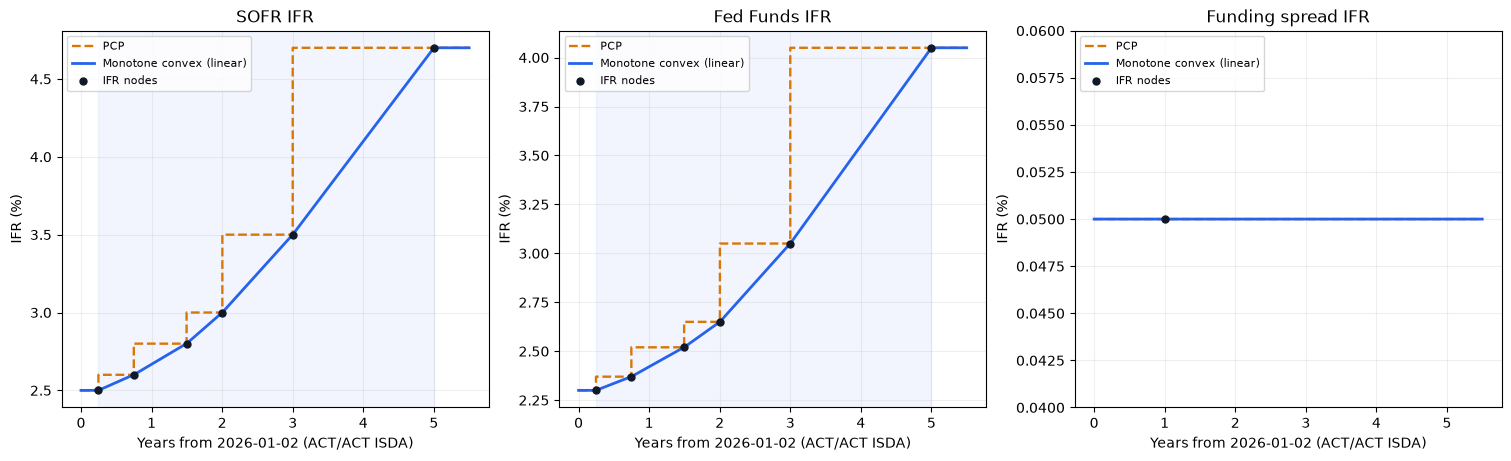

,SOFR IFR,Fed Funds IFR
Node interval; secant slope in bp/year,,
2026-04-02 to 2026-10-02,19.9454,13.9617
2026-10-02 to 2027-07-02,26.7399,20.0549
2027-07-02 to 2028-01-03,39.4606,25.6494
2028-01-03 to 2029-01-02,50.1366,40.1093
2029-01-02 to 2031-01-02,60.0000,50.0000


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plot_methods = ['PIECEWISE_CONSTANT_LEFT_CONTINUOUS', 'MONOTONE_CONVEX']
plot_models = {}
for method in plot_methods:
    plot_build_methods = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {
            **inputs,
            'INTERPOLATION METHOD': method,
            'EXTRAPOLATION METHOD': 'FLAT',
        }) for kind, inputs in curve_inputs
    ])
    plot_models[method] = qfCreateModel(
        '2026-01-02', 'YIELD_CURVE', data_collection, plot_build_methods,
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout='constrained')
slope_columns = {}
for ax, target, title in zip(
    axes, ['SOFR-1B', 'FF-1B', 'SOFR-1B-FLAT'],
    ['SOFR IFR', 'Fed Funds IFR', 'Funding spread IFR'],
):
    student_curve = plot_models['MONOTONE_CONVEX'].retrieve_model_component(
        target,
    ).state_data_interpolator
    times, rates = student_curve.axis1, student_curve.values
    grid = np.unique(np.concatenate((np.linspace(0.0, 5.5, 1400), times)))
    pcp_curve = plot_models[plot_methods[0]].retrieve_model_component(
        target,
    ).state_data_interpolator
    ax.step(grid, [100 * pcp_curve.interpolate(t) for t in grid],
            where='pre', color='#d97706', linestyle='--', label='PCP', linewidth=1.7)
    ax.plot(grid, [100 * student_curve.interpolate(t) for t in grid],
            color='#2563eb', label='Monotone convex (linear)', linewidth=2)
    ax.scatter(times, 100 * rates, color='#111827', s=25, zorder=3, label='IFR nodes')
    if len(times) > 1:
        ax.axvspan(times[0], times[-1], color='#2563eb', alpha=0.06)
        slope_columns[title] = 10000 * np.diff(rates) / np.diff(times)
    else:
        ax.set_ylim(0.04, 0.06)
    ax.set(title=title, xlabel='Years from 2026-01-02 (ACT/ACT ISDA)', ylabel='IFR (%)')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc='upper left')
plt.show()

slope_table = pd.DataFrame(slope_columns, index=[
    f'{start} to {end}' for start, end in zip(node_dates[:-1], node_dates[1:])
])
slope_table.index.name = 'Node interval; secant slope in bp/year'
display(slope_table.round(4))

In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3249.683956872288
Student minus PCP: 341.3973176343243


In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513070154


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12678.268722314897
Student minus PCP: 6455.751209244743


In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7638.9164845796695
Student minus PCP: -712.432423602324


### PV comparison (USD; student minus PCP)

In [9]:
pv_comparison = pd.DataFrame({
    'Product': ['FRA', 'RFR swap', 'Overnight basis swap'],
    'PCP PV (USD)': [fra_pcp_pv, swap_pcp_pv, basis_pcp_pv],
    'Student PV (USD)': [fra_student_pv, swap_student_pv, basis_student_pv],
}).set_index('Product')
pv_comparison['Student minus PCP (USD)'] = (
    pv_comparison['Student PV (USD)'] - pv_comparison['PCP PV (USD)']
)
display(pv_comparison.round(6))

,PCP PV (USD),Student PV (USD),Student minus PCP (USD)
Product,,,
FRA,2908.286639,3249.683957,341.397318
RFR swap,6222.517513,12678.268722,6455.751209
Overnight basis swap,8351.348908,7638.916485,-712.432424


### Interpretation of the PV differences

For increasing node values, the supplied left-continuous PCP method uses the **right-hand node value** on each interval $(t_i,t_{i+1}]$. The linear IFR lies below it between nodes. Consequently the student method has smaller forward integrals, lower projected term rates, and larger discount factors. Both methods retain the same constant 5 bp funding spread; the SOFR reference curve still changes, so funding discount factors change too.

- **FRA:** this product receives 3.2% fixed and pays the projected SOFR rate. The projected rate falls from **2.618197% to 2.550177%**; the payment discount factor rises from **0.97801647 to 0.97843259**. Its PV rises by **$341.397318**.
- **RFR swap:** this product receives 3.4% fixed and pays compounded SOFR. Lower projected SOFR coupons improve its PV, and the larger discount factors increase the fixed-leg PV. The fixed leg gains about **$328.21** and the signed floating leg gains about **$6,127.54**, giving a total improvement of **$6,455.751209**.
- **Overnight basis swap:** this product receives SOFR plus 10 bp and pays Fed Funds. Both projected rates fall, but the received SOFR index leg loses about **$2,951.43** of PV while the paid Fed Funds leg saves about **$2,236.16**. The received spread leg gains about **$2.83** through discounting. The net change is **-$712.432424**. Thus lower forwards do not imply the same PV direction for every product.

These differences result from the interpolation assumption between the same IFR points. They are not calibration errors: the assignment supplies point values directly, and both methods reproduce those values. The PCP discontinuities and the continuous linear segments imply different areas under the IFR curves, which affect projection and discounting.
